# Battle of the Quants 2026: Path-Area Momentum

**Summary.** Momentum is stronger when a stock's past return builds up through many small moves than when it comes from a few large jumps (Da, Gurun & Warachka, 2014). We measure *how* a stock earned its return directly from the shape of its price path: the area between the daily log-price path and its monthly trend lines, divided by the size of the return.

**Main result:** a simple long-only strategy that buys smooth winners beat the benchmark by a wide margin over 2001–2025 (below).

We also test the signal as a zero-weight, zero-beta active portfolio scaled to 5% active volatility.

## Headline result: long-only smooth winners

Buying the smoothest winners each month earned **15.2% a year from 2001 to 2025 vs 8.4% for the benchmark** (cumulative log return 352% vs 201%), with shallower drawdowns along the way.

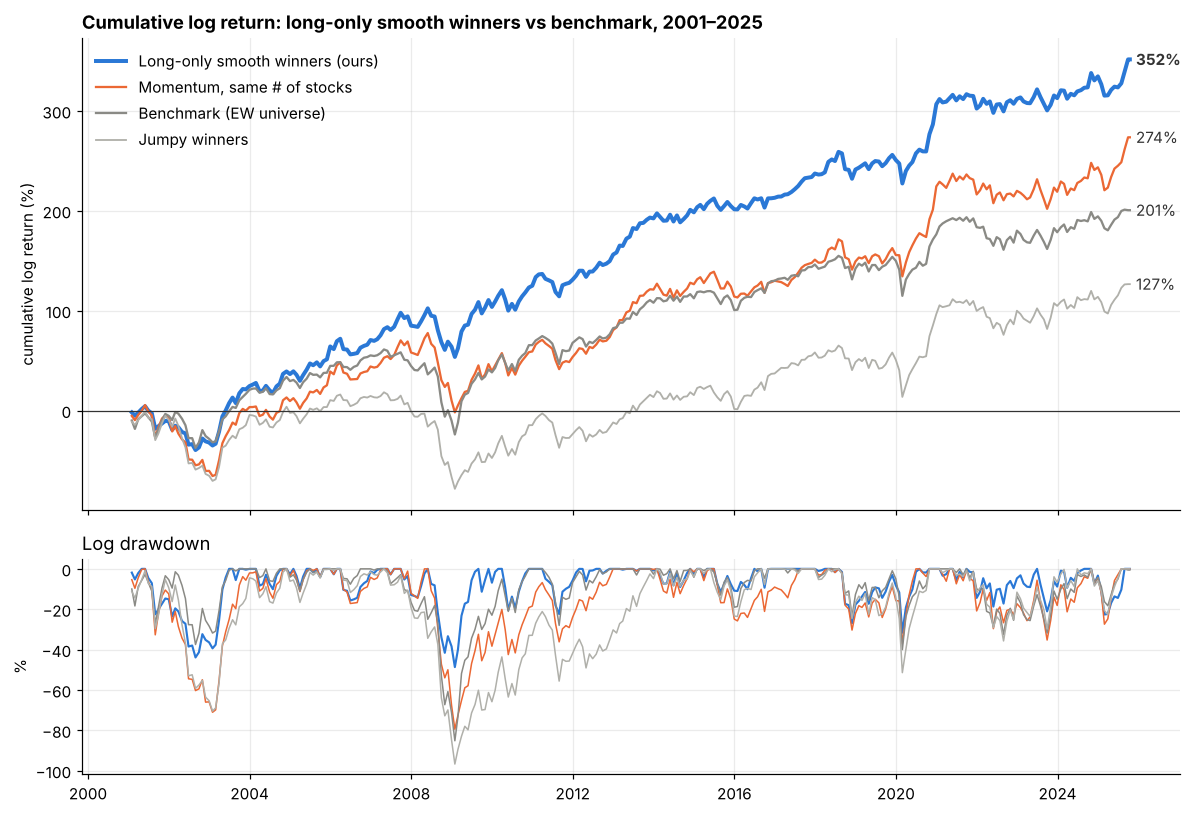

| | **Smooth winners (ours)** | Momentum, same # of stocks | Benchmark (EW universe) |
|---|---|---|---|
| Annual return (CAGR) | **15.2%** | 11.6% | 8.4% |
| Sharpe ratio (no risk-free) | **0.79** | 0.58 | 0.49 |
| Max log drawdown | **−49%** | −79% | −85% |
| Cumulative log return, 2001–2025 | **352%** | 274% | 201% |
| Alpha vs benchmark | **7.9%/yr (t = 3.4)** | 4.3%/yr (t = 1.5) | — |
| Beta | 0.82 | 0.94 | 1.00 |
| Years beating the benchmark | **19 of 25** | 14 of 25 | — |

**The smoother the path, the better the winners.** Within each smoothness quintile we buy the top 20% by 6-month return. Returns fall steadily from the smoothest group to the jumpiest:

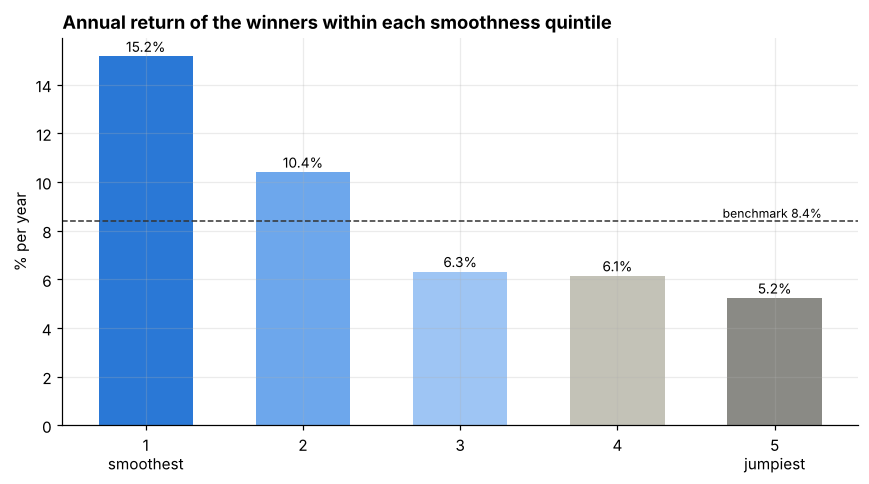

**Why this matters**
- **It isn't just momentum.** Plain momentum with the same number of stocks earns less, with more risk and deeper drawdowns. The smoothness filter is doing real work.
- **Smoother is better, step by step.** Buying the winners from each smoothness quintile earns 15.2%, 10.4%, 6.3%, 6.1% and 5.2% a year from smoothest to jumpiest (Figure 2).
- **The mirror image fails.** The same strategy built from the *jumpiest* stocks earned 5.2% a year, below the benchmark. Smooth gains persist; jumpy ones don't, exactly as the frog-in-the-pan story predicts.
- **It isn't a volatility screen.** Our normalized area has essentially zero correlation with volatility (−0.04).
- **It fits the fund's mandate:** long-only, fully invested, no leverage, monthly rebalancing, ~113 liquid names.

Full statistics are in Section 6; the charts are generated by the code in Section 7 (Figures 1 and 2).

## 1. Idea and motivation

**Starting point: frog-in-the-pan (FIP).** Da, Gurun & Warachka (2014) argue that investors underreact to information that arrives *continuously* in small amounts, like a frog in slowly heating water, and react more fully to *discrete*, attention-grabbing news. They measure discreteness over the formation window with

$$\text{ID} = \operatorname{sgn}(\text{PRET}) \times (\%\text{neg} - \%\text{pos}),$$

where PRET is the formation-period return and %pos and %neg are the shares of up and down days. Momentum is concentrated among stocks with continuous information (low ID).

**Our hypothesis.** ID only counts up and down days, so it depends heavily on the ratio of drift to volatility, not just on how information arrived. In our data, ID has a rank correlation of −0.47 with $|\text{PRET}|/\sigma$. We replace it with a measure built from the shape of the price path itself: the area between the daily log-price path and its straight-line trend, divided by $|\text{PRET}|$. This uses every day of the path rather than just the sign of each day's return. Normalizing by the return asks how much the path wandered per unit of return earned, so the measure separates steady (continuous) paths from jumpy (discrete) ones.

## 2. Data

We use only the original competition dataset (`BotQ_2026_data`): daily data from 2000-01-03 to 2025-10-16, about 2,950 stocks per day and 9,162 distinct `barrid`s, including stocks that later delisted, so there is no survivorship bias. The file is CSV text despite its `.parquet` name, so we convert it once to a slim Parquet file.

Processing choices:
- `return` (daily simple return, in percent) and `specific_risk` (annualized, in percent) are divided by 100. Returns include dividends and are split-adjusted, so all price paths are built from cumulative returns, never from `price`.
- Stocks are identified by `barrid` (tickers change and get reused).
- Month-end values of `specific_risk` and `predicted_beta` feed the optimizer. Stock-months missing either are excluded.
- Forward return = the compounded return over the next calendar month. A stock that stops trading mid-month earns its returns until it disappears and cash (0) after that.

In [1]:
# === Data loading and processing ===
import time
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

pl.Config.set_tbl_width_chars(170); pl.Config.set_float_precision(3); pl.Config.set_tbl_rows(40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GRAY, AQUA = "#2a78d6", "#eb6834", "#8a8a85", "#1baf7a"

LOOKBACK = 6          # formation window (calendar months)
BUCKET = 0.20         # smoothest 20% of stocks by normalized area
IC_SCALE = 0.05       # fund convention: alpha = 0.05 * score * specific_risk
TARGET_VOL = 0.05     # 5% annual active volatility
COST_BPS = 10         # one-way trading cost for after-cost figures
START = "2001-01-01"

def find(names):
    for d in [Path("."), Path(".."), Path("data"), Path("/mnt/user-data/uploads/BotQ_data")]:
        for n in names:
            if (d / n).exists():
                return d / n
    return None

SLIM = find(["botq_slim.parquet"])
if SLIM is None:                          # one-time conversion of the competition CSV
    raw = find(["BotQ_2026_data.parquet", "BotQ_2026_data.csv"])
    SLIM = raw.parent / "botq_slim.parquet"
    (pl.scan_csv(raw, schema_overrides={"cusip": pl.String})
       .select("barrid", "date", "price", "return", "specific_risk", "predicted_beta")
       .with_columns(pl.col("date").str.to_date())
       .sink_parquet(SLIM, compression="zstd"))

t0 = time.time()
panel = (pl.read_parquet(SLIM, columns=["barrid", "date", "return", "specific_risk", "predicted_beta"])
           .with_columns(pl.col("return", "specific_risk") / 100)
           .sort("barrid", "date"))
per_day = panel.group_by("date").len()
print(f"{panel.height:,} stock-days | {panel['barrid'].n_unique():,} stocks | {panel['date'].min()} to {panel['date'].max()}")
print(f"stocks per day: median {per_day['len'].median():.0f} (min {per_day['len'].min()}, max {per_day['len'].max()})")
print(f"missing: return {panel['return'].null_count()}, specific_risk {panel['specific_risk'].null_count()}, "
      f"predicted_beta {panel['predicted_beta'].null_count()} | {time.time()-t0:.0f}s")

19,129,651 stock-days | 9,162 stocks | 2000-01-03 to 2025-10-16
stocks per day: median 2954 (min 2696, max 3160)
missing: return 0, specific_risk 40546, predicted_beta 40546 | 3s


## 3. Signal construction

For each stock and each month in the six-month formation window, we take the daily log-price path and the chord joining the month's first and last close. We measure the absolute area between them and sum it over the six months:

$$A_i = \sum_{m=1}^{6} \int \left|\,\log P_{i,t} - \text{chord}_{i,m}(t)\,\right| dt.$$

We normalize by the size of the formation return:

$$\text{NA}_i = \frac{A_i}{|\text{PRET}_i|}.$$

A small $\text{NA}_i$ means the stock moved steadily along its trend (continuous). A large $\text{NA}_i$ means the path wandered far from the trend relative to what it earned (discrete).

**Signal.** Each month we sort eligible stocks by $\text{NA}_i$, keep the selected 20% bucket, and score stocks inside it by their 6-month momentum z-score. Stocks outside the bucket get a score of zero.

In [2]:
# === Path area and normalized area (NA) ===
# Per stock-month: cumulative log-return path, chord from first to last close of the month,
# exact absolute area between them (trapezoids; crossing segments split into two triangles so
# positive and negative pieces don't cancel). x-unit = one trading day.
t0 = time.time()
f = panel.with_columns(pl.col("return").log1p().cum_sum().over("barrid").alias("lp"),
                       pl.col("date").dt.truncate("1mo").alias("month"))
k = ["barrid", "month"]
f = (f.with_columns(pl.len().over(k).alias("n"), pl.int_range(pl.len()).over(k).alias("i"),
                    pl.col("lp").first().over(k).alias("s"), pl.col("lp").last().over(k).alias("e"))
      .with_columns((pl.col("lp") - (pl.col("s") + (pl.col("e") - pl.col("s")) * pl.col("i")
                     / (pl.col("n") - 1).clip(lower_bound=1))).alias("gap"))
      .with_columns(pl.col("gap").shift(-1).over(k).alias("gap_next")))
a, b = pl.col("gap").abs(), pl.col("gap_next").abs()
piece = pl.when(pl.col("gap") * pl.col("gap_next") >= 0).then((a + b) / 2).otherwise((a * a + b * b) / (2 * (a + b)))

monthly = (f.with_columns(piece.alias("piece")).group_by(k).agg(
              pl.col("piece").sum().alias("area_m"),
              pl.len().cast(pl.Int64).alias("n"),
              ((pl.col("return") + 1).product() - 1).alias("ret_m"),
              pl.col("return").pow(2).sum().alias("ss"),
              (pl.col("return") > 0).sum().cast(pl.Int64).alias("n_pos"),
              (pl.col("return") < 0).sum().cast(pl.Int64).alias("n_neg"),
              pl.col("specific_risk").last(), pl.col("predicted_beta").last())
           .sort("barrid", "month"))
del f

L = LOOKBACK
lr = (pl.col("ret_m") + 1).log()
sig = (monthly.with_columns(
          pl.col("area_m").rolling_sum(L).over("barrid").alias("area6"),
          lr.rolling_sum(L).over("barrid").alias("pret"),                          # 6-month log return
          lr.rolling_sum(11).shift(1).over("barrid").alias("mom12_1"),             # months t-11..t-1
          pl.col("n").rolling_min(L).over("barrid").alias("min_n"),
          (pl.col("ss").rolling_sum(L) / pl.col("n").rolling_sum(L)).sqrt().over("barrid").alias("vol"),
          ((pl.col("n_neg").rolling_sum(L) - pl.col("n_pos").rolling_sum(L)) / pl.col("n").rolling_sum(L))
              .over("barrid").alias("neg_minus_pos"),
          (pl.col("month") - pl.col("month").shift(L - 1).over("barrid")).dt.total_days().alias("span"))
       .filter((pl.col("min_n") >= 2) & (pl.col("span") <= 160))
       .with_columns((pl.col("area6") / pl.col("pret").abs()).alias("NA"),                       # normalized area
                     (pl.col("pret").sign() * pl.col("neg_minus_pos")).alias("fip_id")))         # FIP's ID

# signal date = last trading day of the month; forward return = next calendar month
ends = (panel.select("date").unique().group_by(pl.col("date").dt.truncate("1mo").alias("month"))
             .agg(pl.col("date").max()))
fwd = monthly.select("barrid", pl.col("month").dt.offset_by("-1mo"), pl.col("ret_m").alias("fwd_ret"))
sig = (ends.join(sig, on="month").join(fwd, on=["barrid", "month"], how="left")
           .with_columns(pl.col("fwd_ret").fill_null(0.0))
           .filter((pl.col("date") >= pl.lit(START).str.to_date()) & pl.col("NA").is_finite()
                   & pl.col("specific_risk").is_not_null() & pl.col("predicted_beta").is_not_null()
                   & (pl.col("specific_risk") > 0))
           .sort("date", "barrid"))
print(f"{sig.height:,} stock-months on {sig['date'].n_unique()} month-ends | {time.time()-t0:.0f}s")
med = sig.select(pl.col("pret", "NA", "vol").median()).row(0, named=True)
print(f"medians: 6-month log return {med['pret']:.3f}, NA {med['NA']:.1f}, daily vol {med['vol']:.3f}")

841,434 stock-months on 298 month-ends | 10s
medians: 6-month log return 0.036, NA 21.0, daily vol 0.023


In [3]:
# === Bucket selection and momentum z-scores ===
def zs(c, over="date"):
    return ((pl.col(c) - pl.col(c).mean()) / pl.col(c).std()).over(over)

sig = sig.with_columns(
    ((pl.col("NA").rank("average").over("date") - 1) / (pl.len().over("date") - 1)).alias("na_pct"),
    (pl.col("pret").abs() / (pl.col("vol") * np.sqrt(21 * L))).alias("drift_to_vol"),
).with_columns(
    (pl.col("na_pct") <= BUCKET).alias("smooth"),
    (pl.col("na_pct") >= 1 - BUCKET).alias("jumpy"),
)
sig = sig.with_columns(
    # strategy score: 6-month momentum z-score inside the smoothest bucket, zero outside
    pl.when(pl.col("smooth")).then(zs("pret", ["date", "smooth"])).otherwise(0.0).alias("score_path_area"),
    # mirror image (for comparison): same score inside the jumpiest bucket
    pl.when(pl.col("jumpy")).then(zs("pret", ["date", "jumpy"])).otherwise(0.0).alias("score_jumpy"),
    # plain momentum baselines over all stocks
    zs("pret").alias("score_mom6"),
    zs("mom12_1").fill_null(0.0).alias("score_mom12_1"),   # <12 months of history -> 0
)
SCORES = {"Path-area momentum (ours)": "score_path_area", "Momentum 6m": "score_mom6",
          "Momentum 12-1": "score_mom12_1", "Jumpy-bucket momentum": "score_jumpy"}
for name, c in SCORES.items():
    sig = sig.with_columns((IC_SCALE * pl.col(c) * pl.col("specific_risk")).alias("alpha_" + c))

rc = sig.group_by("date").agg(
    pl.corr("fip_id", "drift_to_vol", method="spearman").alias("FIP ID vs |PRET|/vol"),
    pl.corr("NA", "vol", method="spearman").alias("NA vs volatility"),
    pl.corr("area6", "vol", method="spearman").alias("raw area vs volatility"),
    pl.corr("NA", pl.col("pret").abs(), method="spearman").alias("NA vs |PRET|"),
    pl.corr("NA", "fip_id", method="spearman").alias("NA vs FIP ID"),
).drop("date").mean()
print(f"smooth bucket: {sig.filter('smooth').group_by('date').len()['len'].mean():.0f} stocks per month")
print("Average monthly rank correlations:")
for k_, v_ in rc.row(0, named=True).items():
    print(f"  {k_:<24s} {v_:+.2f}")

smooth bucket: 565 stocks per month
Average monthly rank correlations:
  FIP ID vs |PRET|/vol     -0.48
  NA vs volatility         -0.04
  raw area vs volatility   +0.91
  NA vs |PRET|             -0.86
  NA vs FIP ID             +0.47


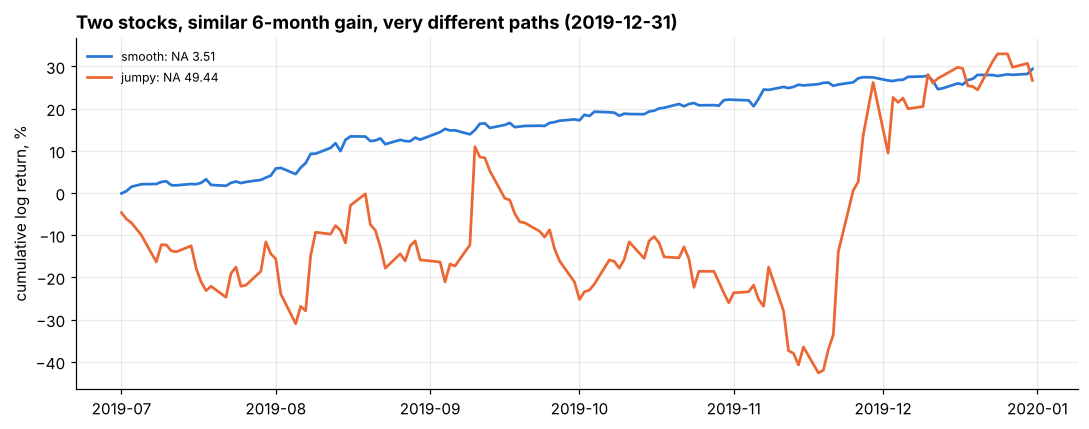

In [4]:
# === Example: a smooth path and a jumpy path with similar 6-month gains ===
fig, ax = plt.subplots(figsize=(10, 4))
d0 = sig.filter(pl.col("date").dt.year() == 2019)["date"].max()
cand = sig.filter((pl.col("date") == d0) & pl.col("pret").is_between(0.25, 0.40)).sort("NA")
for s_, color, lab in [(cand.row(0, named=True), BLUE, "smooth"), (cand.row(-1, named=True), ORANGE, "jumpy")]:
    start = pl.Series([d0]).dt.truncate("1mo").dt.offset_by(f"-{L-1}mo")[0]
    p = panel.filter((pl.col("barrid") == s_["barrid"]) & pl.col("date").is_between(start, d0))
    ax.plot(p["date"], np.cumsum(np.log1p(p["return"].to_numpy())) * 100, color=color, lw=1.8, label=f"{lab}: NA {s_['NA']:.2f}")
ax.set_title(f"Two stocks, similar 6-month gain, very different paths ({d0})", loc="left", fontweight="bold"); ax.set_ylabel("cumulative log return, %")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout(); plt.show()

## 4. Signal effectiveness

We test whether the signal predicts next-month returns. The tests are the monthly rank IC with its t-statistic, quintile spreads, and the alpha the signal adds over plain momentum.

In [5]:
# === Information coefficient (IC) ===
# Monthly Spearman rank correlation between each score and next-month return.
ic = sig.group_by("date").agg(
    [pl.corr(c, "fwd_ret", method="spearman").alias(n) for n, c in SCORES.items()]
    + [pl.corr(pl.col("pret").filter(pl.col(b)), pl.col("fwd_ret").filter(pl.col(b)), method="spearman").alias(f"Momentum inside {b} bucket")
       for b in ("smooth", "jumpy")]
).sort("date")

def ic_row(name):
    x = ic[name].fill_nan(None).drop_nulls().to_numpy()
    return {"score": name, "mean_IC": x.mean(), "IC_t_stat": x.mean() / x.std(ddof=1) * np.sqrt(len(x)),
            "IC_IR_ann": x.mean() / x.std(ddof=1) * np.sqrt(12), "share_positive": (x > 0).mean(), "months": len(x)}

ic_table = pl.DataFrame([ic_row(c) for c in ic.columns[1:]])
for r_ in ic_table.iter_rows(named=True):
    print(f"{r_['score']:<30s} mean IC {r_['mean_IC']:+.3f}  (t = {r_['IC_t_stat']:.2f})")

Path-area momentum (ours)      mean IC +0.016  (t = 3.02)
Momentum 6m                    mean IC +0.019  (t = 2.29)
Momentum 12-1                  mean IC +0.028  (t = 3.28)
Jumpy-bucket momentum          mean IC +0.003  (t = 2.47)
Momentum inside smooth bucket  mean IC +0.029  (t = 2.74)
Momentum inside jumpy bucket   mean IC +0.008  (t = 2.46)


In [6]:
# === Quintile / decile returns ===
# Momentum quintiles formed separately inside the smoothest bucket, inside the jumpiest bucket,
# and across all stocks. Equal-weighted next-month returns.
def quintiles(df, label):
    q = (df.with_columns(((pl.col("pret").rank("ordinal").over("date") - 1) * 5 // pl.len().over("date") + 1).alias("q"))
           .group_by("date", "q").agg(pl.col("fwd_ret").mean()))
    w = q.pivot(on="q", index="date", values="fwd_ret", sort_columns=True).sort("date")
    spread = (w["5"] - w["1"]).to_numpy()
    row = {"group": label, **{f"Q{i}": w[str(i)].mean() * 1200 for i in range(1, 6)},
           "Q5-Q1_ann_%": spread.mean() * 1200, "t_stat": spread.mean() / spread.std(ddof=1) * np.sqrt(len(spread))}
    return row, spread

groups = [("Smooth bucket (low NA)", sig.filter(pl.col("smooth"))), ("Jumpy bucket (high NA)", sig.filter(pl.col("jumpy"))), ("All stocks", sig)]
rows, spreads = zip(*[quintiles(d, n) for n, d in groups])
qt = pl.DataFrame(list(rows))
d = spreads[0] - spreads[1]
print(f"Smooth minus jumpy momentum spread: {d.mean()*1200:.2f}% per year, t = {d.mean()/d.std(ddof=1)*np.sqrt(len(d)):.2f}")

for r_ in rows:
    print(f"{r_['group']:<24s} Q5-Q1 {r_['Q5-Q1_ann_%']:+.1f}%/yr  (t = {r_['t_stat']:.2f})")

Smooth minus jumpy momentum spread: 1.61% per year, t = 0.25
Smooth bucket (low NA)   Q5-Q1 +4.2%/yr  (t = 0.59)
Jumpy bucket (high NA)   Q5-Q1 +2.6%/yr  (t = 1.71)
All stocks               Q5-Q1 +3.5%/yr  (t = 0.80)


In [7]:
# === Alpha over plain momentum (6m and 12-1) ===
# Portfolio weights come from the optimizer described in Section 5 (defined here so the test can run first).
VOL_WINDOW, VOL_MIN = 12, 6

def optimal_active_weights(alpha, spec_risk, beta):
    # maximize alpha'h  s.t.  sum(h)=0, beta'h=0, h'Dh = target^2, D = diag(specific variance)
    w = 1.0 / spec_risk**2
    A = np.column_stack([np.ones_like(alpha), beta])
    lam = np.linalg.solve(A.T @ (w[:, None] * A), A.T @ (w * alpha))
    h = w * (alpha - A @ lam)
    return h * TARGET_VOL / np.sqrt(np.sum(spec_risk**2 * h**2))

def run_active(alpha_col):
    rows, W = [], []
    for (d,), g in sig.group_by(["date"], maintain_order=True):
        h = optimal_active_weights(g[alpha_col].to_numpy(), g["specific_risk"].to_numpy(), g["predicted_beta"].to_numpy())
        r = g["fwd_ret"].to_numpy()
        rows.append({"date": d, "active_raw": float(h @ r), "bench": float(r.mean()), "net": float(h.sum()),
                     "beta": float(h @ g["predicted_beta"].to_numpy()), "gross_raw": float(np.abs(h).sum())})
        W.append(pl.DataFrame({"date": [d] * len(h), "barrid": g["barrid"], "h": h}))
    res = (pl.DataFrame(rows).sort("date")
           .with_columns((pl.col("active_raw").rolling_std(VOL_WINDOW, min_samples=VOL_MIN).shift(1) * np.sqrt(12)).alias("trail_vol"))
           .with_columns((TARGET_VOL / pl.col("trail_vol")).alias("scale")).drop_nulls("scale")
           .with_columns((pl.col("active_raw") * pl.col("scale")).alias("active"),
                         (pl.col("gross_raw") * pl.col("scale")).alias("gross")))
    w = pl.concat(W).join(res.select("date", "scale"), on="date").with_columns(pl.col("h") * pl.col("scale"))
    wide = w.pivot(on="date", index="barrid", values="h", sort_columns=True).fill_null(0.0)
    turn = np.abs(np.diff(wide.drop("barrid").to_numpy(), axis=1)).sum(axis=0) / 2
    res = res.with_columns(pl.Series("turnover", np.concatenate([[np.nan], turn])[: res.height]))
    return res

t0 = time.time()
RES = {name: run_active("alpha_" + c) for name, c in SCORES.items()}
print(f"backtests done in {time.time()-t0:.0f}s")

ours = RES["Path-area momentum (ours)"]
reg_rows = []
for base in ["Momentum 6m", "Momentum 12-1"]:
    j = ours.select("date", "active").join(RES[base].select("date", pl.col("active").alias("m")), on="date")
    y, x = j["active"].to_numpy(), j["m"].to_numpy()
    X = np.column_stack([np.ones_like(x), x]); coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ coef; se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * e.var(ddof=2))
    reg_rows.append({"regressed_on": base, "alpha_ann": coef[0] * 12, "alpha_t": coef[0] / se[0],
                     "loading": coef[1], "R2": 1 - e.var() / y.var()})
for r_ in reg_rows:
    print(f"Active path-area returns on {r_['regressed_on']}: alpha {r_['alpha_ann']:+.2%}/yr (t = {r_['alpha_t']:.2f}), "
          f"loading {r_['loading']:.2f}, R2 {r_['R2']:.2f}")

backtests done in 3s
Active path-area returns on Momentum 6m: alpha +1.01%/yr (t = 1.67), loading 0.89, R2 0.76
Active path-area returns on Momentum 12-1: alpha +0.46%/yr (t = 0.53), loading 0.75, R2 0.53


## 5. Portfolio construction

### Primary strategy: long-only smooth winners
Each month-end *t*:
1. Rank all eligible stocks by normalized area (NA) and keep the smoothest **20%**.
2. Within that group, buy the top **20%** by 6-month return (≈ 113 stocks).
3. Equal-weight, fully invested, no shorting, no leverage. Hold over month *t+1*, then rebalance.

**Benchmark.** The competition file has no index or market-cap weights, so the Russell 3000 itself can't be rebuilt. The benchmark is the **equal-weighted eligible universe** (≈ 2,800 stocks per month), with the same timing.

### Secondary: active portfolio (zero weight, zero beta, 5% active volatility)
1. **Alpha.** $\alpha_i = 0.05 \times \text{score}_i \times \sigma^{spec}_i$ (the fund's convention). The score is the momentum z-score inside the smoothest 20% NA bucket, and zero elsewhere.
2. **Optimizer.** Maximize $\alpha^\top h$ subject to $\mathbf 1^\top h = 0$, $\beta^\top h = 0$ (Barra predicted beta) and $h^\top D h = 0.05^2$, where $D$ holds the specific variances. Closed form: $h \propto D^{-1}(\alpha - A\lambda)$ with $A = [\mathbf 1, \beta]$.
3. **Risk scaling.** The competition data has no factor covariance matrix, so each month the weights are rescaled by $5\% / \hat\sigma$, where $\hat\sigma$ is trailing 12-month realized active volatility through month *t−1* (no look-ahead).

In [8]:
# === Optimizer and backtest ===
# Active backtests ran in the previous section (run_active). Here: the long-only fund-mandate version.
def long_only(bucket_col):
    rows, held = [], []
    for (d,), g in sig.group_by(["date"], maintain_order=True):
        b = g.filter(pl.col(bucket_col))
        p = b.sort("pret", descending=True).head(max(1, int(b.height * 0.20)))
        rows.append({"date": d, "port": p["fwd_ret"].mean(), "bench": g["fwd_ret"].mean(), "n": p.height})
        held.append(set(p["barrid"].to_list()))
    out = pl.DataFrame(rows).sort("date")
    turn = [np.nan] + [0.5 * sum(abs((1 / len(a) if s in a else 0) - (1 / len(c) if s in c else 0)) for s in a | c)
                       for a, c in zip(held[1:], held[:-1])]
    return out.with_columns(pl.Series("turnover", turn), (pl.col("port") - pl.col("bench")).alias("active"))

def top_n_momentum(n_like):
    rows, held = [], []
    n_by_date = dict(zip(n_like["date"].to_list(), n_like["n"].to_list()))
    for (d,), g in sig.group_by(["date"], maintain_order=True):
        p = g.sort("pret", descending=True).head(n_by_date[d])
        rows.append({"date": d, "port": p["fwd_ret"].mean(), "bench": g["fwd_ret"].mean()})
        held.append(set(p["barrid"].to_list()))
    turn = [np.nan] + [0.5 * sum(abs((1 / len(a) if s in a else 0) - (1 / len(c) if s in c else 0)) for s in a | c)
                       for a, c in zip(held[1:], held[:-1])]
    return pl.DataFrame(rows).sort("date").with_columns(pl.Series("turnover", turn), (pl.col("port") - pl.col("bench")).alias("active"))

LO = long_only("smooth")
LO_jumpy = long_only("jumpy")
LO_mom = top_n_momentum(LO)          # plain momentum with the same number of stocks
print(f"Long-only: {LO.height} months, ~{LO['n'].mean():.0f} holdings")

Long-only: 298 months, ~113 holdings


## 6. Performance

### Performance summary (all portfolios)

In [9]:
# === Headline: long-only smooth winners ===
def headline(name, r):
    p, bm = r["port"].to_numpy(), r["bench"].to_numpy(); act = p - bm
    beta = np.cov(p, bm)[0, 1] / np.var(bm, ddof=1); a = p - beta * bm
    cum = np.cumsum(np.log1p(p)); dd = cum - np.maximum.accumulate(np.maximum(cum, 0))
    yrs = r.with_columns(pl.col("date").dt.year().alias("y")).group_by("y").agg(
        ((pl.col("port") + 1).product() - (pl.col("bench") + 1).product()).alias("d"))
    return {"portfolio": name,
            "annual_return (CAGR)": np.prod(1 + p) ** (12 / len(p)) - 1,
            "annual_vol": p.std(ddof=1) * np.sqrt(12),
            "sharpe_no_rf": p.mean() / p.std(ddof=1) * np.sqrt(12),
            "max_log_drawdown": dd.min(),
            "beta": beta,
            "alpha_per_yr": a.mean() * 12, "alpha_t": None if name.startswith("Benchmark") else a.mean() / a.std(ddof=1) * np.sqrt(len(a)),
            "excess_vs_bench_per_yr": act.mean() * 12,
            "cumulative_log_return": float(np.log1p(p).sum()),
            "years_beating_bench": None if name.startswith("Benchmark") else f"{(yrs['d'] > 0).sum()} of {yrs.height}"}

bench_only = LO.select("date", pl.col("bench").alias("port"), "bench")
act_port = ours.select("date", (pl.col("active") + pl.col("bench")).alias("port"), "bench")
rows = [headline("Long-only smooth winners (ours)", LO), headline("Momentum, same # of stocks", LO_mom),
        headline("Jumpy winners (discrete twin)", LO_jumpy), headline("Active portfolio, total (0 beta, 5% active vol)", act_port),
        headline("Benchmark (EW universe)", bench_only)]
after_cost = {"Long-only smooth winners (ours)": LO, "Momentum, same # of stocks": LO_mom, "Jumpy winners (discrete twin)": LO_jumpy,
              "Active portfolio, total (0 beta, 5% active vol)": ours}
for r_ in rows:
    src_ = after_cost.get(r_["portfolio"])
    if src_ is None:
        r_["IR_after_costs"] = None; continue
    a_ = src_["active"].to_numpy(); cost_ = np.nanmean(src_["turnover"].to_numpy()) * 12 * COST_BPS / 1e4
    r_["IR_after_costs"] = (a_.mean() * 12 - cost_) / (a_.std(ddof=1) * np.sqrt(12))
d = (LO["port"] - LO_mom["port"]).to_numpy()
print(f"Smooth winners minus same-size momentum: {d.mean()*12:+.2%}/yr (t = {d.mean()/d.std(ddof=1)*np.sqrt(len(d)):.2f})")
d = (LO["port"] - LO_jumpy["port"]).to_numpy()
print(f"Smooth winners minus jumpy winners:      {d.mean()*12:+.2%}/yr (t = {d.mean()/d.std(ddof=1)*np.sqrt(len(d)):.2f})")
pl.DataFrame(rows).select(
    "portfolio", pl.col("annual_return (CAGR)").alias("return/yr"), pl.col("annual_vol").alias("vol"),
    pl.col("sharpe_no_rf").alias("Sharpe"), pl.col("max_log_drawdown").alias("max log DD"),
    pl.col("alpha_per_yr").alias("alpha/yr"), "alpha_t", pl.col("IR_after_costs").alias(f"IR after {COST_BPS}bps"),
    pl.col("years_beating_bench").alias("years > bench"))

Smooth winners minus same-size momentum: +2.36%/yr (t = 1.53)
Smooth winners minus jumpy winners:      +8.64%/yr (t = 3.42)


portfolio,return/yr,vol,Sharpe,max log DD,alpha/yr,alpha_t,IR after 10bps,years > bench
str,f64,f64,f64,f64,f64,f64,f64,str
"""Long-only smooth winners (ours…",0.152,0.206,0.792,-0.487,0.079,3.446,0.455,"""19 of 25"""
"""Momentum, same # of stocks""",0.116,0.241,0.580,-0.795,0.043,1.531,0.227,"""14 of 25"""
"""Jumpy winners (discrete twin)""",0.052,0.227,0.340,-0.967,-0.027,-1.663,-0.446,"""8 of 25"""
"""Active portfolio, total (0 bet…",0.120,0.200,0.671,-0.745,0.036,3.007,0.340,"""15 of 25"""
"""Benchmark (EW universe)""",0.084,0.209,0.493,-0.852,0.000,null,null,null


In [10]:
# === Yearly volatility and return ===
yt = (LO.with_columns(pl.col("date").dt.year().alias("year"))
        .group_by("year").agg(((pl.col("port") + 1).product() - 1).alias("smooth winners return"),
                              ((pl.col("bench") + 1).product() - 1).alias("benchmark return"),
                              (pl.col("port").std() * np.sqrt(12)).alias("smooth winners vol"),
                              (pl.col("bench").std() * np.sqrt(12)).alias("benchmark vol"))
        .with_columns((pl.col("smooth winners return") - pl.col("benchmark return")).alias("difference"))
        .sort("year"))
act_years = ours.with_columns(pl.col("date").dt.year().alias("y")).group_by("y").agg(pl.col("active").sum())
print(f"Long-only smooth winners beat the benchmark in {(yt['difference'] > 0).sum()} of {yt.height} years; "
      f"the active portfolio was positive in {(act_years['active'] > 0).sum()} of {act_years.height} years")
yt

Long-only smooth winners beat the benchmark in 19 of 25 years; the active portfolio was positive in 16 of 25 years


year,smooth winners return,benchmark return,smooth winners vol,benchmark vol,difference
i32,f64,f64,f64,f64,f64
2001,-0.102,-0.052,0.178,0.286,-0.050
2002,-0.192,-0.206,0.189,0.256,0.013
2003,0.761,0.634,0.219,0.156,0.127
2004,0.127,0.091,0.174,0.137,0.036
2005,0.320,0.165,0.192,0.140,0.155
2006,0.066,0.111,0.167,0.094,-0.045
2007,0.154,-0.101,0.174,0.122,0.255
2008,-0.189,-0.421,0.255,0.313,0.232
2009,0.489,0.621,0.305,0.326,-0.131


In [11]:
# === Lag, leverage requirements, rebalance rate, turnover, constraint checks ===
to_lo, to_act = np.nanmean(LO["turnover"].to_numpy()), np.nanmean(ours["turnover"].to_numpy())
pl.DataFrame([
    {"item": "Signal lag", "long-only (primary)": "closes through month-end t; trade at close t; hold month t+1", "active portfolio": "same"},
    {"item": "Rebalance rate", "long-only (primary)": "monthly", "active portfolio": "monthly"},
    {"item": "Holdings", "long-only (primary)": f"~{LO['n'].mean():.0f} stocks, equal weight", "active portfolio": "all eligible stocks, concentrated in smooth bucket"},
    {"item": "Gross leverage", "long-only (primary)": "1.00 (fully invested, no shorts)", "active portfolio": f"avg {ours['gross'].mean():.2f}, max {ours['gross'].max():.2f}"},
    {"item": "One-way turnover / month", "long-only (primary)": f"{to_lo:.0%}", "active portfolio": f"{to_act:.0%}"},
    {"item": f"Cost drag at {COST_BPS} bps", "long-only (primary)": f"{to_lo*12*COST_BPS/1e4:.2%}/yr", "active portfolio": f"{to_act*12*COST_BPS/1e4:.2%}/yr"},
    {"item": "Net weight / beta", "long-only (primary)": "100% invested / beta 0.82 (realized)",
     "active portfolio": f"max |net| {ours['net'].abs().max()*ours['scale'].max():.0e} / max |beta| {ours['beta'].abs().max()*ours['scale'].max():.0e}"},
    {"item": "Realized volatility", "long-only (primary)": f"{LO['port'].std()*np.sqrt(12):.1%} total",
     "active portfolio": f"{ours['active'].std()*np.sqrt(12):.1%} active (target 5%)"},
])

item,long-only (primary),active portfolio
str,str,str
"""Signal lag""","""closes through month-end t; tr…","""same"""
"""Rebalance rate""","""monthly""","""monthly"""
"""Holdings""","""~113 stocks, equal weight""","""all eligible stocks, concentra…"
"""Gross leverage""","""1.00 (fully invested, no short…","""avg 1.06, max 3.04"""
"""One-way turnover / month""","""51%""","""50%"""
"""Cost drag at 10 bps""","""0.61%/yr""","""0.60%/yr"""
"""Net weight / beta""","""100% invested / beta 0.82 (rea…","""max |net| 4e-14 / max |beta| 3…"
"""Realized volatility""","""20.6% total""","""6.1% active (target 5%)"""


## 7. Visuals

### Figure 1: Long-only smooth winners — cumulative log return and log drawdown vs the benchmark

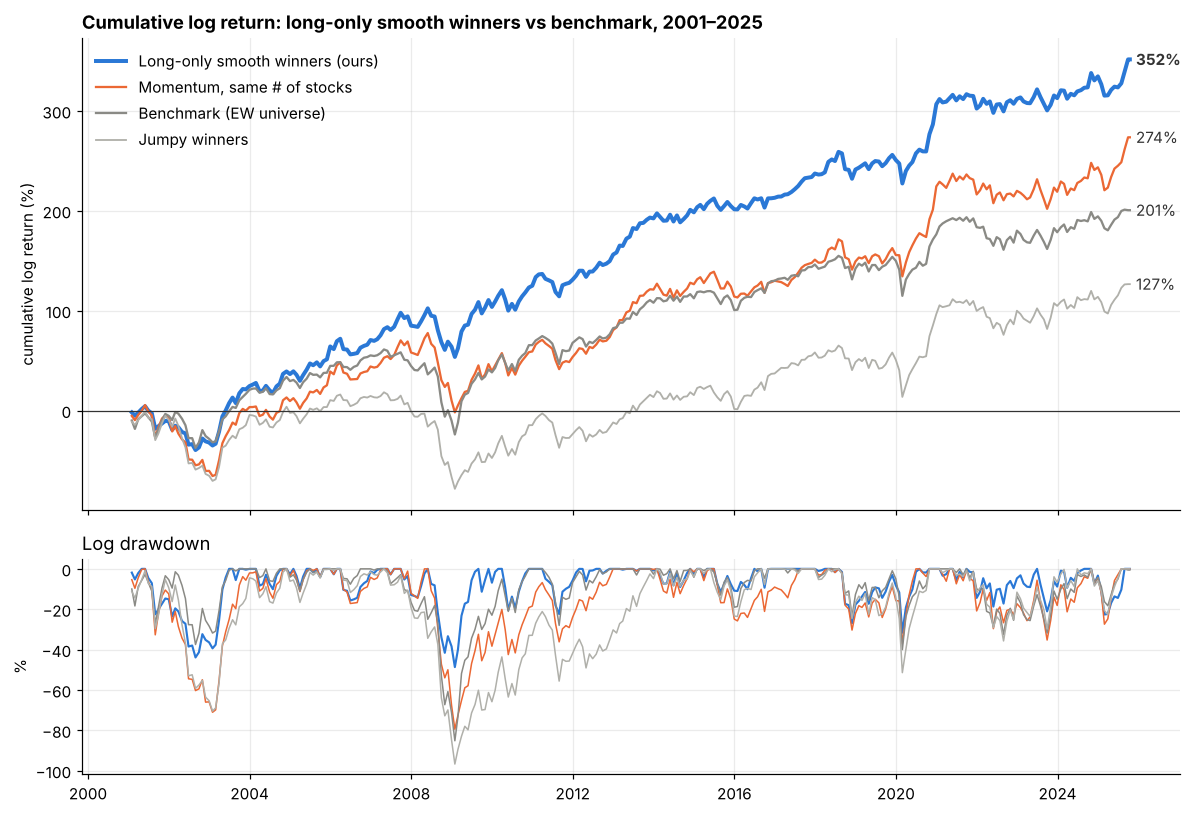

Worst log drawdown: smooth winners -49%, momentum -79%, benchmark -85%


In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
lines = [("Long-only smooth winners (ours)", LO, BLUE, 2.6), ("Momentum, same # of stocks", LO_mom, ORANGE, 1.5),
         ("Benchmark (EW universe)", bench_only, GRAY, 1.5), ("Jumpy winners", LO_jumpy, "#b0b0aa", 1.2)]
for name, r, color, lw in lines:
    cum = np.cumsum(np.log1p(r["port"].to_numpy())) * 100
    ax1.plot(r["date"], cum, color=color, lw=lw, label=name)
    ax1.annotate(f"{cum[-1]:.0f}%", (r["date"][-1], cum[-1]), xytext=(4, 0), textcoords="offset points", va="center",
                 fontsize=10, fontweight="bold" if color == BLUE else "normal", color="#333")
    ax2.plot(r["date"], cum - np.maximum.accumulate(np.maximum(cum, 0)), color=color, lw=1.4 if color == BLUE else 1)
ax1.axhline(0, color="#333", lw=0.8)
ax1.set_ylabel("cumulative log return (%)")
ax1.set_title("Cumulative log return: long-only smooth winners vs benchmark, 2001–2025", loc="left", fontweight="bold", fontsize=12)
ax1.legend(frameon=False, loc="upper left")
ax2.set_title("Log drawdown", loc="left"); ax2.set_ylabel("%")
fig.tight_layout(); plt.show()
ldd = lambda x: (lambda cm: (cm - np.maximum.accumulate(np.maximum(cm, 0))).min())(np.cumsum(np.log1p(x)) * 100)
print(f"Worst log drawdown: smooth winners {ldd(LO['port'].to_numpy()):.0f}%, momentum {ldd(LO_mom['port'].to_numpy()):.0f}%, benchmark {ldd(LO['bench'].to_numpy()):.0f}%")

### Figure 2: Smoother paths, better winners

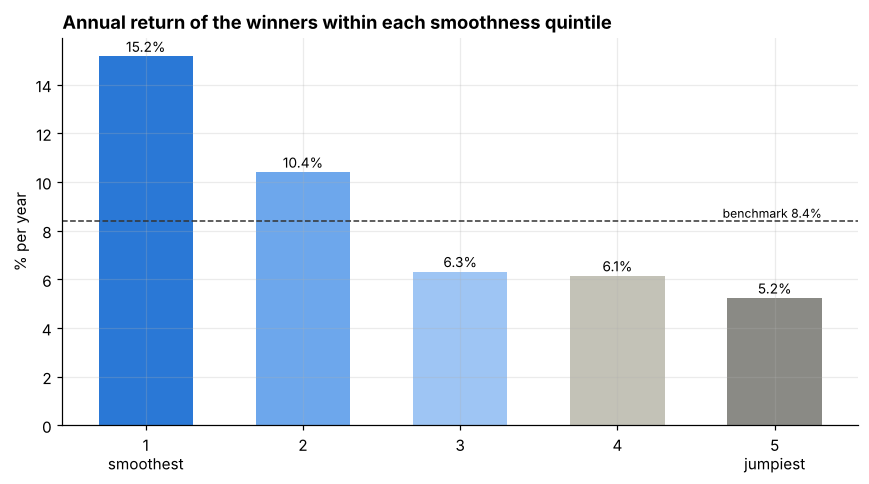

Winners by smoothness quintile (annual return): Q1 15.2%, Q2 10.4%, Q3 6.3%, Q4 6.1%, Q5 5.2%


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ladder = []
for q_ in range(1, 6):
    rows_ = []
    for (d,), g in sig.group_by(["date"], maintain_order=True):
        gq = g.filter(((pl.col("na_pct") * 5).floor().clip(upper_bound=4) + 1) == q_)
        p = gq.sort("pret", descending=True).head(max(1, int(gq.height * 0.20)))
        rows_.append(p["fwd_ret"].mean())
    r_ = np.array(rows_); ladder.append(np.prod(1 + r_) ** (12 / len(r_)) - 1)
bars = ax.bar(range(5), np.array(ladder) * 100, color=[BLUE, "#6da7ec", "#9ec5f4", "#c3c2b7", GRAY], width=0.6)
ax.axhline(LO_bench_cagr := (np.prod(1 + LO["bench"].to_numpy()) ** (12 / LO.height) - 1) * 100, color="#333", lw=1, ls="--")
ax.annotate(f"benchmark {LO_bench_cagr:.1f}%", (4.3, LO_bench_cagr), va="bottom", ha="right", fontsize=8)
for i_, v_ in enumerate(ladder): ax.annotate(f"{v_*100:.1f}%", (i_, v_ * 100), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(range(5), ["1\nsmoothest", "2", "3", "4", "5\njumpiest"])
ax.set_title("Winners from each smoothness quintile: annual return", loc="left", fontweight="bold"); ax.set_ylabel("% per year")
ax.set_title("Annual return of the winners within each smoothness quintile", loc="left", fontweight="bold")
fig.tight_layout(); plt.show()
print("Winners by smoothness quintile (annual return): " + ", ".join(f"Q{i+1} {v*100:.1f}%" for i, v in enumerate(ladder)))

### Figure 3: Calendar-year returns, smooth winners vs the benchmark (equal-weighted universe; Russell 3000 weights are not in the competition data)

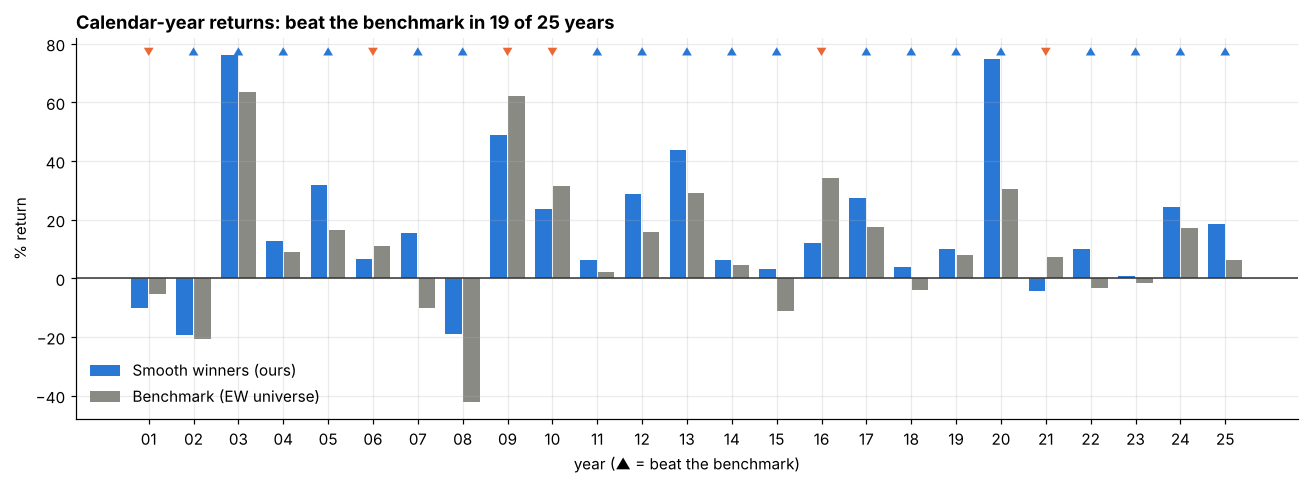

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(yt.height); w = 0.4
ax.bar(x - w / 2, yt["smooth winners return"] * 100, w * 0.92, color=BLUE, label="Smooth winners (ours)")
ax.bar(x + w / 2, yt["benchmark return"] * 100, w * 0.92, color=GRAY, label="Benchmark (EW universe)")
for xi, d in zip(x, yt["difference"].to_numpy()):
    ax.annotate("▲" if d > 0 else "▼", (xi, ax.get_ylim()[1] * 0.97), ha="center", va="top", fontsize=7,
                color=BLUE if d > 0 else ORANGE)
ax.axhline(0, color="#333", lw=1)
ax.set_xticks(x, [str(y)[2:] for y in yt["year"]]); ax.set_xlabel("year (▲ = beat the benchmark)")
ax.set_ylabel("% return"); ax.legend(frameon=False, loc="lower left")
ax.set_title(f"Calendar-year returns: beat the benchmark in {(yt['difference'] > 0).sum()} of {yt.height} years", loc="left", fontweight="bold")
fig.tight_layout(); plt.show()

### Figure 4: Active portfolio version (0 beta, 0 weight, 5% active volatility)

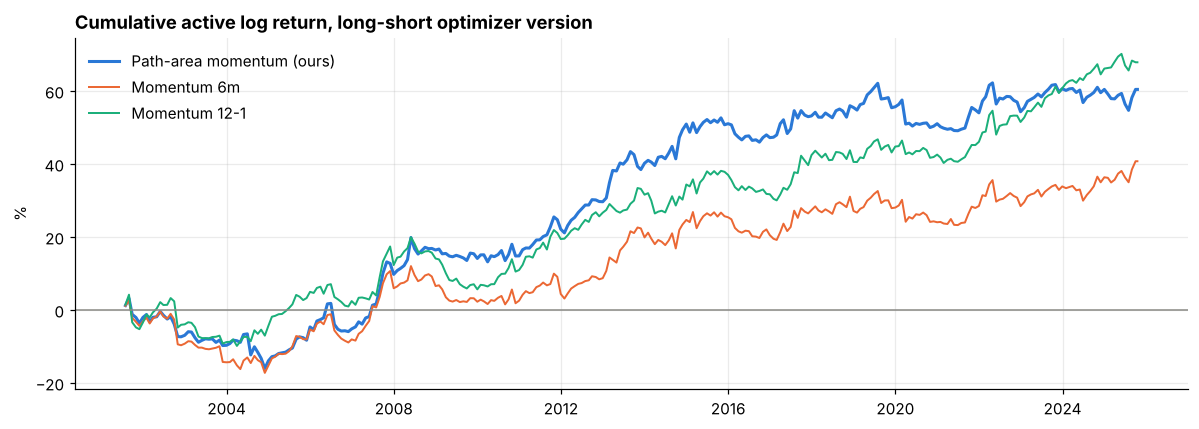

In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
for name, color, lw in [("Path-area momentum (ours)", BLUE, 2.0), ("Momentum 6m", ORANGE, 1.3), ("Momentum 12-1", AQUA, 1.3)]:
    r = RES[name]; cum = np.cumsum(np.log1p(r["active"].to_numpy())) * 100
    ax.plot(r["date"], cum, color=color, lw=lw, label=name)
ax.axhline(0, color=GRAY, lw=1)
ax.set_title("Cumulative active log return, long-short optimizer version", loc="left", fontweight="bold")
ax.set_ylabel("%"); ax.legend(frameon=False, loc="upper left"); fig.tight_layout(); plt.show()

## 8. Conclusion

**Main result.** A simple long-only portfolio of smooth winners (the smoothest 20% of stocks by normalized path area, then the top 20% of those by 6-month return) earned **15.2% a year from 2001 to 2025 vs 8.4% for the benchmark**. Its cumulative log return was **352% vs 201%**, with a **higher Sharpe ratio (0.79 vs 0.49)**, a **shallower worst log drawdown (−49% vs −85%)**, and **7.9%/yr alpha (t = 3.4)**. It beat the benchmark in **19 of 25 years**, and the strategy fits the fund's long-only, unlevered mandate.

**Why we believe it.**
- Plain momentum with the same number of stocks did clearly worse (11.6%/yr, Sharpe 0.58, log drawdown −79%), so smoothness adds value beyond momentum.
- The mirror image, jumpy winners, *lost* to the benchmark (5.2%/yr), matching the frog-in-the-pan prediction that gradual information is under-priced while attention-grabbing jumps are not.
- The measure is not a volatility screen: raw path area is 91% rank-correlated with volatility, and our normalized area is not (−0.04).

**Active portfolio (zero weight, zero beta, 5% active volatility).** The same idea as a long-short optimizer signal has an **IR of 0.44 (t = 2.2)**, or 0.34 after 10 bps costs. That beats plain 6-month momentum (IR 0.31; alpha 1.0%/yr, t = 1.7) but not 12-1 momentum (IR 0.50).

**Caveats.**
- The benchmark is the equal-weighted universe; the competition data has no Russell 3000 weights. Sharpe ratios exclude the risk-free rate.
- Inside the smooth bucket, the winner-minus-loser spread is not significant (4.2%/yr, t = 0.6). Much of the edge comes from *which* stocks enter the bucket: normalized area is strongly related to the size of the move (−0.86), so the bucket concentrates large, steady movers.
- The specification was chosen after testing several variants, so out-of-sample confirmation matters. Costs are modeled at 10 bps per trade, with no market-impact model.

**Next step.** Run the strategy through the Silver Fund's `sf-backtester` with the Barra risk model and Russell 3000 cap weights. That code is written and waiting on `grp_quant` data access.

## References

- Da, Z., Gurun, U. G., & Warachka, M. (2014). Frog in the Pan: Continuous Information and Momentum. *Review of Financial Studies*, 27(7), 2171–2218.